# Clustering Analysis of Multilingual Entity Embeddings

This notebook performs comprehensive clustering analysis on entity embeddings:
- **K-Means**: Find optimal k and cluster entities
- **Hierarchical**: Analyze dendrogram and splitting patterns
- **DBSCAN**: Density-based clustering
- **HDBSCAN**: Hierarchical density-based clustering
- **Evaluation**: Compare methods using multiple metrics
- **Interpretation**: TF-IDF keywords, culture/country correlation
- **Hierarchical Analysis**: Do countries or cultures split first?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import logging
from tqdm import tqdm

# Set up logging
logging.basicConfig(
    level=logging.INFO, format="%(asctime)s - %(name)s - %(levelname)s - %(message)s"
)

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Plotting settings
plt.style.use("default")
sns.set_palette("husl")

print(f"✓ Random seed set to {RANDOM_SEED}")
print(f"✓ Libraries imported successfully")

✓ Random seed set to 42
✓ Libraries imported successfully


In [2]:
from src.data.database import EntityDatabase
from src.embeddings import load_cached_embeddings
from src.clustering import (
    cluster_kmeans,
    cluster_dbscan,
    cluster_hdbscan,
    cluster_hierarchical,
    find_optimal_k_kmeans,
    compare_clustering_methods,
    analyze_hierarchical_dendrogram,
    analyze_cluster_hierarchy,
    extract_tfidf_keywords,
)
from src.visualization import (
    plot_clustering_metrics_comparison,
    plot_optimal_k_analysis,
    plot_clusters_2d,
    plot_clusters_3d_interactive,
    plot_cluster_composition,
    plot_hierarchy_purity_analysis,
)
from src.analysis import (
    analyze_cluster_group_correlation,
    analyze_cluster_purity,
    test_hierarchical_split_order,
    calculate_contingency_table,
)

## Load Data

In [3]:
df = pd.read_csv("../data/experiment/selected_entities.csv")
print(f"✓ Loaded {len(df)} selected entities")
print(f"  Columns: {df.columns.tolist()}")

# Display basic statistics
print("\n" + "=" * 80)
print("DATA OVERVIEW")
print("=" * 80)
print(f"Total entities: {len(df)}")
print(f"\nEntity types: {df['type'].value_counts().to_dict()}")
print(f"\nCultures: {df['culture'].value_counts().to_dict()}")
print(f"\nTop 10 countries: {df['country'].value_counts().head(10).to_dict()}")

✓ Loaded 26098 selected entities
  Columns: ['id', 'wikidata_id', 'type', 'culture', 'country', 'created_at', 'label', 'labels']

DATA OVERVIEW
Total entities: 26098

Entity types: {'person': 26098}

Cultures: {'Western': 7007, 'Latin American': 5973, 'East Asian': 4508, 'Arabic': 3836, 'African': 2718, 'South Asian': 1494, 'Southeast Asian': 562}

Top 10 countries: {'Brazil': 1908, 'Japan': 1789, 'United Kingdom': 1777, 'France': 1757, 'United States': 1756, 'Germany': 1717, 'Argentina': 1695, 'Morocco': 1542, 'Mexico': 1424, 'South Africa': 1412}


## loading embeddings

In [4]:
# Load cached embeddings (choose which language or combined)
# Options: 'en', 'fr', 'ar', or 'combined'
language_choice = "en"  # Change as needed
cache_dir = Path('../data/embeddings')
model_name = "intfloat_multilingual-e5-large"

embeddings_data = load_cached_embeddings(
        language= language_choice,
        model_name=model_name,
        save_dir=cache_dir
    )

embeddings = embeddings_data['embeddings']

print(f"✓ Loaded embeddings: {embeddings.shape}")
print(f"  Language: {language_choice}")
print(f"  Embedding dimension: {embeddings.shape[1]}")

# Check for NaN or Inf
if np.any(np.isnan(embeddings)):
    print("⚠ Warning: NaN values detected in embeddings")
if np.any(np.isinf(embeddings)):
    print("⚠ Warning: Inf values detected in embeddings")

2026-01-01 17:01:07,463 - src.embeddings.text_embedder - INFO - Loading cached embeddings from ../data/embeddings/embeddings_en_intfloat_multilingual-e5-large.pkl
2026-01-01 17:01:07,514 - src.embeddings.text_embedder - INFO - Loaded embeddings shape: (26098, 1024)
2026-01-01 17:01:07,515 - src.embeddings.text_embedder - INFO - Number of entities: 26098


✓ Loaded embeddings: (26098, 1024)
  Language: en
  Embedding dimension: 1024


In [12]:
embeddings.keys()

dict_keys(['embeddings', 'entity_ids', 'language', 'model_name', 'shape', 'metadata'])

In [34]:
# ============================================================================
# CELL 6: Normalize Embeddings
# ============================================================================
from sklearn.preprocessing import normalize

embeddings_normalized = normalize(embeddings, norm='l2', axis=1)

print(f"✓ Embeddings normalized")

✓ Embeddings normalized


✓ PCA applied: 200 components
  Variance explained: 75.78%
  Variance by first 10 components: 17.42%


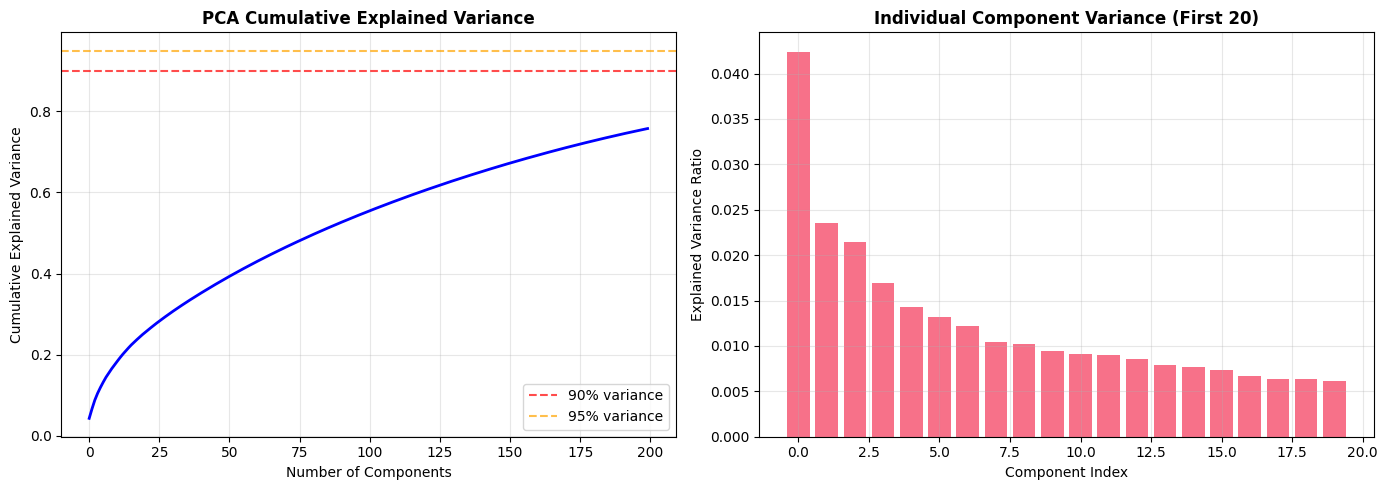

✓ Variance plot saved


In [35]:
# ============================================================================
# CELL 7: PCA Dimensionality Reduction
# ============================================================================
from sklearn.decomposition import PCA

# Choose number of components (50 or 100)
n_components = 200  # or 100

pca = PCA(
    n_components=min(n_components, embeddings_normalized.shape[1]),
    random_state=RANDOM_SEED,
)
embeddings_pca = pca.fit_transform(embeddings_normalized)

print(f"✓ PCA applied: {embeddings_pca.shape[1]} components")
print(f"  Variance explained: {pca.explained_variance_ratio_.sum():.2%}")
print(
    f"  Variance by first 10 components: {pca.explained_variance_ratio_[:10].sum():.2%}"
)

# Plot explained variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cumulative variance
ax = axes[0]
ax.plot(np.cumsum(pca.explained_variance_ratio_), "b-", linewidth=2)
ax.axhline(0.9, color="r", linestyle="--", alpha=0.7, label="90% variance")
ax.axhline(0.95, color="orange", linestyle="--", alpha=0.7, label="95% variance")
ax.set_xlabel("Number of Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("PCA Cumulative Explained Variance", fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3)

# Individual variance
ax = axes[1]
ax.bar(
    range(min(20, len(pca.explained_variance_ratio_))),
    pca.explained_variance_ratio_[:20],
)
ax.set_xlabel("Component Index")
ax.set_ylabel("Explained Variance Ratio")
ax.set_title("Individual Component Variance (First 20)", fontweight="bold")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../data/results_resumes/pca_variance_analysis.png", dpi=300, bbox_inches="tight"
)
plt.show()
print("✓ Variance plot saved")


In [36]:
# normalizing pca embeddings

embeddings_pca = normalize(embeddings_pca, norm='l2', axis=1)


2026-01-01 20:37:21,170 - src.clustering.cluster_methods - INFO - Finding optimal k in range range(2, 50, 4)



FINDING OPTIMAL K FOR K-MEANS


2026-01-01 20:37:26,113 - src.clustering.cluster_methods - INFO - k=2: silhouette=0.044, DB=4.208, CH=1214.6
2026-01-01 20:37:30,637 - src.clustering.cluster_methods - INFO - k=6: silhouette=0.032, DB=4.918, CH=596.8
2026-01-01 20:37:35,704 - src.clustering.cluster_methods - INFO - k=10: silhouette=0.029, DB=4.696, CH=423.8
2026-01-01 20:37:40,632 - src.clustering.cluster_methods - INFO - k=14: silhouette=0.031, DB=4.525, CH=344.0
2026-01-01 20:37:46,105 - src.clustering.cluster_methods - INFO - k=18: silhouette=0.034, DB=4.294, CH=294.5
2026-01-01 20:37:51,506 - src.clustering.cluster_methods - INFO - k=22: silhouette=0.033, DB=4.309, CH=259.0
2026-01-01 20:37:57,175 - src.clustering.cluster_methods - INFO - k=26: silhouette=0.035, DB=4.260, CH=231.9
2026-01-01 20:38:03,539 - src.clustering.cluster_methods - INFO - k=30: silhouette=0.035, DB=4.149, CH=211.7
2026-01-01 20:38:09,387 - src.clustering.cluster_methods - INFO - k=34: silhouette=0.034, DB=4.176, CH=194.3
2026-01-01 20:38:15,

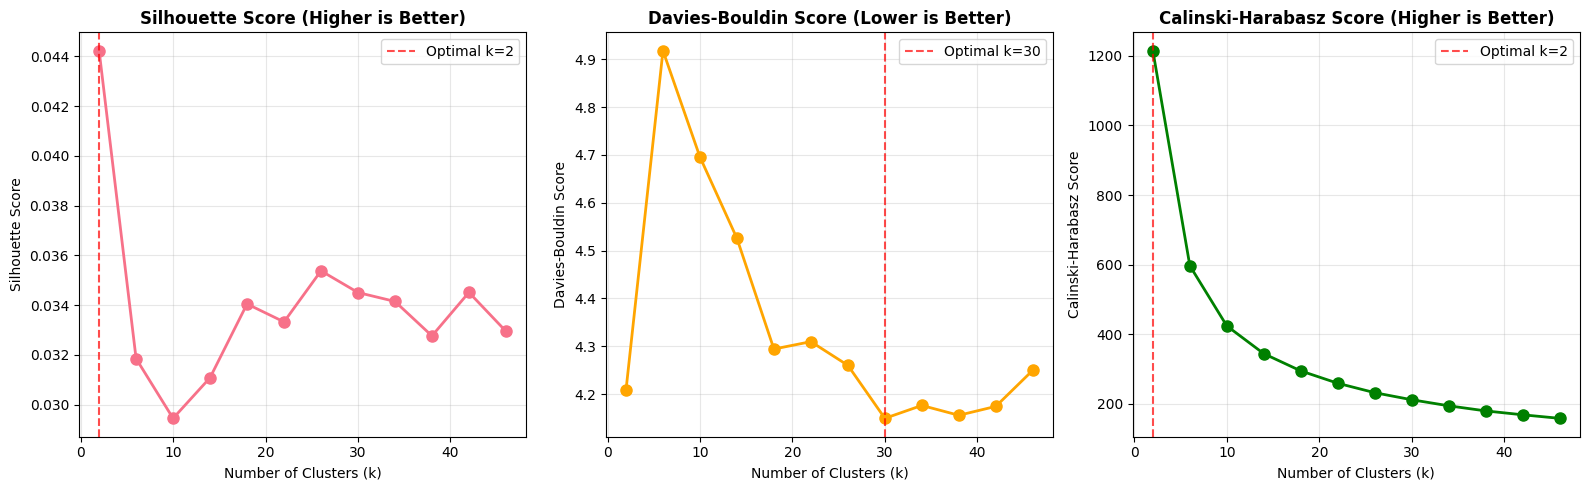


Optimal k values:
  silhouette: k=2
  davies_bouldin: k=30
  calinski_harabasz: k=2

✓ Using k=2 for K-Means


In [37]:
# ============================================================================
# CELL 8: Find Optimal K for K-Means
# ============================================================================
print("\n" + "=" * 80)
print("FINDING OPTIMAL K FOR K-MEANS")
print("=" * 80)

k_range = range(2, 50, 4)
optimal_k_results = find_optimal_k_kmeans(
    embeddings_pca, k_range=k_range, random_state=RANDOM_SEED
)

# Plot optimal k analysis
fig = plot_optimal_k_analysis(optimal_k_results, figsize=(16, 5))
plt.savefig(
    "../data/results_resumes/optimal_k_analysis.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("\nOptimal k values:")
for metric, k in optimal_k_results["optimal_k"].items():
    print(f"  {metric}: k={k}")

# Choose optimal k (you can adjust based on results)
optimal_k = optimal_k_results["optimal_k"]["silhouette"]
print(f"\n✓ Using k={optimal_k} for K-Means")


In [38]:
# ============================================================================
# CELL 9: Perform K-Means Clustering
# ============================================================================
print("\n" + "=" * 80)
print("K-MEANS CLUSTERING")
print("=" * 80)

labels_kmeans = cluster_kmeans(
    embeddings_pca, n_clusters=optimal_k, random_state=RANDOM_SEED
)
df["cluster_kmeans"] = labels_kmeans

print(f"✓ K-Means clustering complete")
print(f"  Number of clusters: {len(set(labels_kmeans))}")
print(f"\nCluster sizes:")
for cluster_id in sorted(set(labels_kmeans)):
    count = (labels_kmeans == cluster_id).sum()
    print(
        f"  Cluster {cluster_id}: {count} entities ({100*count/len(labels_kmeans):.1f}%)"
    )


2026-01-01 23:27:52,048 - src.clustering.cluster_methods - INFO - K-Means clustering: 2 clusters
2026-01-01 23:27:52,249 - src.clustering.cluster_methods - INFO - K-Means complete: 2 unique clusters



K-MEANS CLUSTERING
✓ K-Means clustering complete
  Number of clusters: 2

Cluster sizes:
  Cluster 0: 18276 entities (70.0%)
  Cluster 1: 7822 entities (30.0%)


In [39]:
# ============================================================================
# CELL 10: Hierarchical Clustering
# ============================================================================
print("\n" + "=" * 80)
print("HIERARCHICAL CLUSTERING")
print("=" * 80)

# Try different linkage methods
linkage_methods = ["ward", "complete", "average"]
hierarchical_results = {}

for method in linkage_methods:
    print(f"\nTrying {method} linkage...")
    labels_hier = cluster_hierarchical(
        embeddings_pca, n_clusters=optimal_k, linkage=method, metric="euclidean"
    )
    hierarchical_results[method] = labels_hier
    df[f"cluster_hierarchical_{method}"] = labels_hier

# Use ward for main analysis
labels_hierarchical = hierarchical_results["ward"]
df["cluster_hierarchical"] = labels_hierarchical

print(f"\n✓ Hierarchical clustering complete")
print(f"  Using 'ward' linkage for main analysis")
print(f"  Number of clusters: {len(set(labels_hierarchical))}")

2026-01-01 23:27:54,305 - src.clustering.cluster_methods - INFO - Hierarchical clustering: 2 clusters, linkage=ward, metric=euclidean



HIERARCHICAL CLUSTERING

Trying ward linkage...


2026-01-01 23:28:24,902 - src.clustering.cluster_methods - INFO - Hierarchical complete: 2 unique clusters
2026-01-01 23:28:24,903 - src.clustering.cluster_methods - INFO - Hierarchical clustering: 2 clusters, linkage=complete, metric=euclidean



Trying complete linkage...


2026-01-01 23:28:54,909 - src.clustering.cluster_methods - INFO - Hierarchical complete: 2 unique clusters
2026-01-01 23:28:54,910 - src.clustering.cluster_methods - INFO - Hierarchical clustering: 2 clusters, linkage=average, metric=euclidean



Trying average linkage...


2026-01-01 23:29:24,617 - src.clustering.cluster_methods - INFO - Hierarchical complete: 2 unique clusters



✓ Hierarchical clustering complete
  Using 'ward' linkage for main analysis
  Number of clusters: 2


2026-01-01 23:29:24,622 - src.clustering.cluster_methods - INFO - Creating dendrogram: method=ward, metric=euclidean
2026-01-01 23:29:24,623 - src.clustering.cluster_methods - INFO - Sampling 1000 points from 26098
2026-01-01 23:29:24,659 - src.clustering.cluster_methods - INFO - Dendrogram created



DENDROGRAM VISUALIZATION


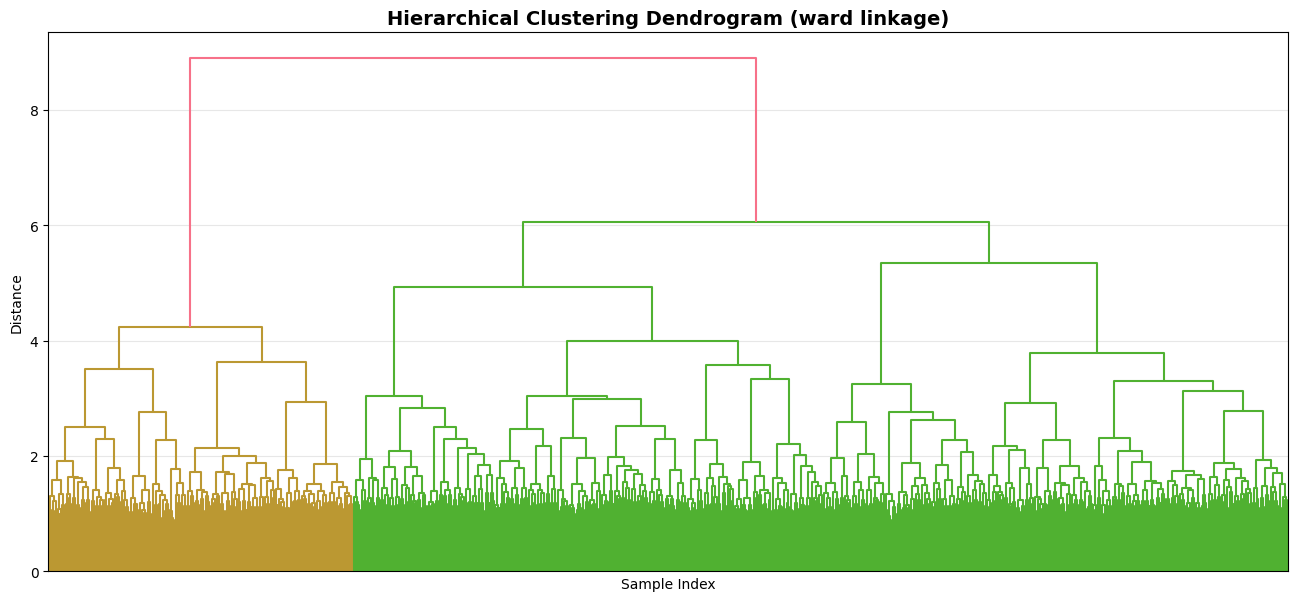

✓ Dendrogram saved


In [40]:
# ============================================================================
# CELL 11: Dendrogram Analysis
# ============================================================================
print("\n" + "=" * 80)
print("DENDROGRAM VISUALIZATION")
print("=" * 80)

# Create dendrogram (sample if too many points)
linkage_matrix, fig = analyze_hierarchical_dendrogram(
    embeddings_pca, method="ward", metric="euclidean", max_samples=1000, figsize=(16, 7)
)

plt.savefig("../data/results_resumes/dendrogram.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Dendrogram saved")



DBSCAN CLUSTERING


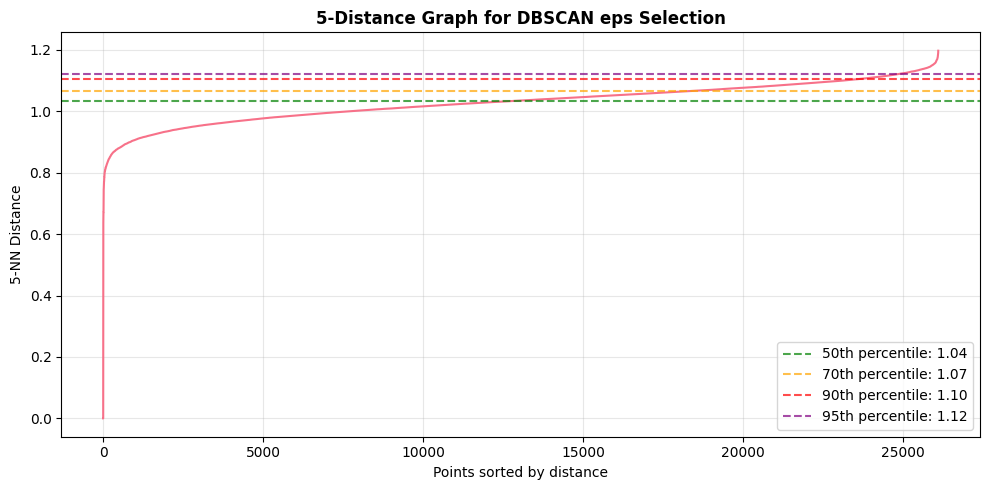

2026-01-01 23:29:42,485 - src.clustering.cluster_methods - INFO - DBSCAN clustering: eps=1.0353013277053833, min_samples=5



Trying different eps values...
------------------------------------------------------------


2026-01-01 23:29:46,161 - src.clustering.cluster_methods - INFO - DBSCAN complete: 1 clusters, 0 noise points
2026-01-01 23:29:46,163 - src.clustering.cluster_methods - INFO - DBSCAN clustering: eps=1.050368309020996, min_samples=5


eps=1.035: 1 clusters, 0 noise (0.0%)


2026-01-01 23:29:50,114 - src.clustering.cluster_methods - INFO - DBSCAN complete: 1 clusters, 0 noise points
2026-01-01 23:29:50,118 - src.clustering.cluster_methods - INFO - DBSCAN clustering: eps=1.0654660701751708, min_samples=5


...

eps=1.065: 1 clusters, 0 noise (0.0%)


2026-01-01 23:29:58,139 - src.clustering.cluster_methods - INFO - DBSCAN complete: 1 clusters, 0 noise points
2026-01-01 23:29:58,142 - src.clustering.cluster_methods - INFO - DBSCAN clustering: eps=1.050368309020996, min_samples=5


eps=1.083: 1 clusters, 0 noise (0.0%)

⚠️  No suitable eps found automatically. Using manual value.
   Trying eps=1.050

✓ Selected eps: 1.050
  Using min_samples: 5


2026-01-01 23:30:01,767 - src.clustering.cluster_methods - INFO - DBSCAN complete: 1 clusters, 0 noise points



✓ DBSCAN clustering complete
  Number of clusters: 1
  Noise points: 0 (0.0%)

⚠️  WARNING: Still only 1 cluster!
   DBSCAN may not be suitable for this data.
   Consider using HDBSCAN instead (Cell 13).


In [41]:
# ============================================================================
# CELL 12: DBSCAN Clustering
# ============================================================================
print("\n" + "=" * 80)
print("DBSCAN CLUSTERING")
print("=" * 80)

from sklearn.neighbors import NearestNeighbors

# Calculate k-distance for eps selection
k = 5
nbrs = NearestNeighbors(n_neighbors=k).fit(embeddings_pca)
distances, indices = nbrs.kneighbors(embeddings_pca)
distances = np.sort(distances[:, -1])

# Plot k-distance graph
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(distances)
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"{k}-NN Distance")
ax.set_title(f"{k}-Distance Graph for DBSCAN eps Selection", fontweight="bold")
ax.grid(True, alpha=0.3)

# Add reference lines for different percentiles
percentiles = [50, 70, 90, 95]
colors = ['green', 'orange', 'red', 'purple']
for p, color in zip(percentiles, colors):
    eps_p = np.percentile(distances, p)
    ax.axhline(eps_p, color=color, linestyle='--', alpha=0.7,
               label=f'{p}th percentile: {eps_p:.2f}')

ax.legend()
plt.tight_layout()
plt.savefig(
    "../data/results_resumes/dbscan_eps_selection.png", dpi=300, bbox_inches="tight"
)
plt.show()

# Try different eps values to find good clustering
print("\nTrying different eps values...")
print("-" * 60)

eps_candidates = [
    np.percentile(distances, 50),  # Median
    np.percentile(distances, 60),
    np.percentile(distances, 70),
    np.percentile(distances, 80),
]

min_samples = 5
best_eps = None
best_n_clusters = 0

for eps_value in eps_candidates:
    labels_test = cluster_dbscan(embeddings_pca, eps=eps_value, min_samples=min_samples)
    n_clusters = len(set(labels_test)) - (1 if -1 in labels_test else 0)
    n_noise = list(labels_test).count(-1)

    print(f"eps={eps_value:.3f}: {n_clusters} clusters, "
          f"{n_noise} noise ({100*n_noise/len(labels_test):.1f}%)")

    # Choose eps with reasonable number of clusters (2-20) and not too much noise
    if 2 <= n_clusters <= 20 and n_noise < 0.5 * len(labels_test):
        if n_clusters > best_n_clusters:
            best_eps = eps_value
            best_n_clusters = n_clusters

# If no good eps found, use a manual value
if best_eps is None:
    print("\n⚠️  No suitable eps found automatically. Using manual value.")
    # Rule of thumb: try eps around the "elbow" of the k-distance plot
    # Usually between 50th-70th percentile
    best_eps = np.percentile(distances, 60)
    print(f"   Trying eps={best_eps:.3f}")

print(f"\n✓ Selected eps: {best_eps:.3f}")
print(f"  Using min_samples: {min_samples}")

# Final DBSCAN with best eps
labels_dbscan = cluster_dbscan(embeddings_pca, eps=best_eps, min_samples=min_samples)
df["cluster_dbscan"] = labels_dbscan

n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = list(labels_dbscan).count(-1)

print(f"\n✓ DBSCAN clustering complete")
print(f"  Number of clusters: {n_clusters}")
print(f"  Noise points: {n_noise} ({100*n_noise/len(labels_dbscan):.1f}%)")

# Warning if still problematic
if n_clusters == 1:
    print("\n⚠️  WARNING: Still only 1 cluster!")
    print("   DBSCAN may not be suitable for this data.")
    print("   Consider using HDBSCAN instead (Cell 13).")
elif n_noise > 0.5 * len(labels_dbscan):
    print("\n⚠️  WARNING: Over 50% noise points!")
    print("   Try increasing eps or decreasing min_samples.")

In [42]:
# ============================================================================
# CELL 13: HDBSCAN Clustering
# ============================================================================
print("\n" + "=" * 80)
print("HDBSCAN CLUSTERING")
print("=" * 80)

# Try different parameter combinations
print("Testing different HDBSCAN parameters...")
print("-" * 60)

# Parameter candidates
min_cluster_size_candidates = [
    max(int(len(df) * 0.005), 5),  # 0.5% of data
    max(int(len(df) * 0.01), 10),  # 1% of data
    max(int(len(df) * 0.02), 15),  # 2% of data
]

min_samples_candidates = [1, 3, 5]

best_params = None
best_n_clusters = 0
best_noise_ratio = 1.0
results = []

for min_cluster_size in min_cluster_size_candidates:
    for min_samples_val in min_samples_candidates:
        labels_test = cluster_hdbscan(
            embeddings_pca,
            min_cluster_size=min_cluster_size,
            min_samples=min_samples_val
        )

        n_clusters = len(set(labels_test)) - (1 if -1 in labels_test else 0)
        n_noise = list(labels_test).count(-1)
        noise_ratio = n_noise / len(labels_test)

        print(f"min_cluster_size={min_cluster_size}, min_samples={min_samples_val}: "
              f"{n_clusters} clusters, {n_noise} noise ({100*noise_ratio:.1f}%)")

        results.append({
            'min_cluster_size': min_cluster_size,
            'min_samples': min_samples_val,
            'n_clusters': n_clusters,
            'noise_ratio': noise_ratio
        })

        # Choose parameters with:
        # 1. Reasonable number of clusters (2-20)
        # 2. Less than 30% noise (more lenient than 50%)
        # 3. Maximize number of clusters while keeping noise low
        if (2 <= n_clusters <= 20 and
            noise_ratio < 0.3 and
            n_clusters > best_n_clusters):
            best_params = (min_cluster_size, min_samples_val)
            best_n_clusters = n_clusters
            best_noise_ratio = noise_ratio

# If no good params found with <30% noise, accept up to 40%
if best_params is None:
    print("\n⚠️  No params with <30% noise. Trying <40% noise...")
    for result in results:
        if (2 <= result['n_clusters'] <= 20 and
            result['noise_ratio'] < 0.4 and
            result['n_clusters'] > best_n_clusters):
            best_params = (result['min_cluster_size'], result['min_samples'])
            best_n_clusters = result['n_clusters']
            best_noise_ratio = result['noise_ratio']

# If still no good params, use most lenient
if best_params is None:
    print("\n⚠️  Still no suitable params. Using most lenient settings.")
    best_params = (min_cluster_size_candidates[0], min_samples_candidates[0])
    print(f"   Defaulting to min_cluster_size={best_params[0]}, min_samples={best_params[1]}")

min_cluster_size, min_samples_hdbscan = best_params
print(f"\n✓ Selected parameters:")
print(f"  min_cluster_size: {min_cluster_size}")
print(f"  min_samples: {min_samples_hdbscan}")
print(f"  Expected: ~{best_n_clusters} clusters, ~{100*best_noise_ratio:.1f}% noise")

# Final HDBSCAN with best parameters
labels_hdbscan = cluster_hdbscan(
    embeddings_pca,
    min_cluster_size=min_cluster_size,
    min_samples=min_samples_hdbscan
)
df["cluster_hdbscan"] = labels_hdbscan

n_clusters = len(set(labels_hdbscan)) - (1 if -1 in labels_hdbscan else 0)
n_noise = list(labels_hdbscan).count(-1)

print(f"\n✓ HDBSCAN clustering complete")
print(f"  Number of clusters: {n_clusters}")
print(f"  Noise points: {n_noise} ({100*n_noise/len(labels_hdbscan):.1f}%)")

# Interpretation
if n_noise > 0.4 * len(labels_hdbscan):
    print("\n⚠️  WARNING: Over 40% noise points!")
    print("   HDBSCAN may not be suitable for this embedding space.")
    print("   This suggests uniform density (common for embeddings).")
    print("   → Recommendation: Focus on K-Means or Hierarchical clustering results.")
elif n_clusters < 2:
    print("\n⚠️  WARNING: Less than 2 clusters found!")
    print("   HDBSCAN couldn't find distinct density-based clusters.")
    print("   → Recommendation: Use K-Means or Hierarchical clustering instead.")
else:
    print(f"\n✓ HDBSCAN found {n_clusters} density-based clusters")
    print(f"   Noise ratio: {100*n_noise/len(labels_hdbscan):.1f}%")

2026-01-01 23:30:17,672 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=130, min_samples=1



HDBSCAN CLUSTERING
Testing different HDBSCAN parameters...
------------------------------------------------------------


2026-01-01 23:30:47,881 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 2 clusters, 11385 noise points
2026-01-01 23:30:47,897 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=130, min_samples=3


min_cluster_size=130, min_samples=1: 2 clusters, 11385 noise (43.6%)


2026-01-01 23:33:01,082 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 2 clusters, 13785 noise points
2026-01-01 23:33:01,084 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=130, min_samples=5


...

min_cluster_size=521, min_samples=3: 3 clusters, 20624 noise (79.0%)


2026-01-01 23:45:01,613 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 2 clusters, 21973 noise points
2026-01-01 23:45:01,615 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=130, min_samples=1


min_cluster_size=521, min_samples=5: 2 clusters, 21973 noise (84.2%)

⚠️  No params with <30% noise. Trying <40% noise...

⚠️  Still no suitable params. Using most lenient settings.
   Defaulting to min_cluster_size=130, min_samples=1

✓ Selected parameters:
  min_cluster_size: 130
  min_samples: 1
  Expected: ~0 clusters, ~100.0% noise


2026-01-01 23:45:31,117 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 2 clusters, 11385 noise points



✓ HDBSCAN clustering complete
  Number of clusters: 2
  Noise points: 11385 (43.6%)

⚠️  WARNING: Over 40% noise points!
   HDBSCAN may not be suitable for this embedding space.
   This suggests uniform density (common for embeddings).
   → Recommendation: Focus on K-Means or Hierarchical clustering results.


2026-01-01 23:46:30,679 - src.clustering.cluster_methods - INFO - Comparing 4 clustering methods



COMPARING CLUSTERING METHODS


2026-01-01 23:46:39,322 - src.clustering.cluster_methods - WARNING - Skipping DBSCAN: insufficient samples/clusters
2026-01-01 23:46:40,789 - src.clustering.cluster_methods - INFO - Comparison complete for 3 methods



Comparison Results:
                method  n_clusters  n_noise  noise_pct  silhouette  davies_bouldin  calinski_harabasz  min_cluster_size  max_cluster_size  avg_cluster_size  std_cluster_size
0              K-Means           2        0   0.000000    0.044228        4.208080        1214.589844              7822             18276           13049.0            5227.0
1  Hierarchical (Ward)           2        0   0.000000    0.034584        4.594490         934.479126              6830             19268           13049.0            6219.0
2              HDBSCAN           2    11385  43.624032    0.007446        3.771065          52.059917               212             14501            7356.5            7144.5


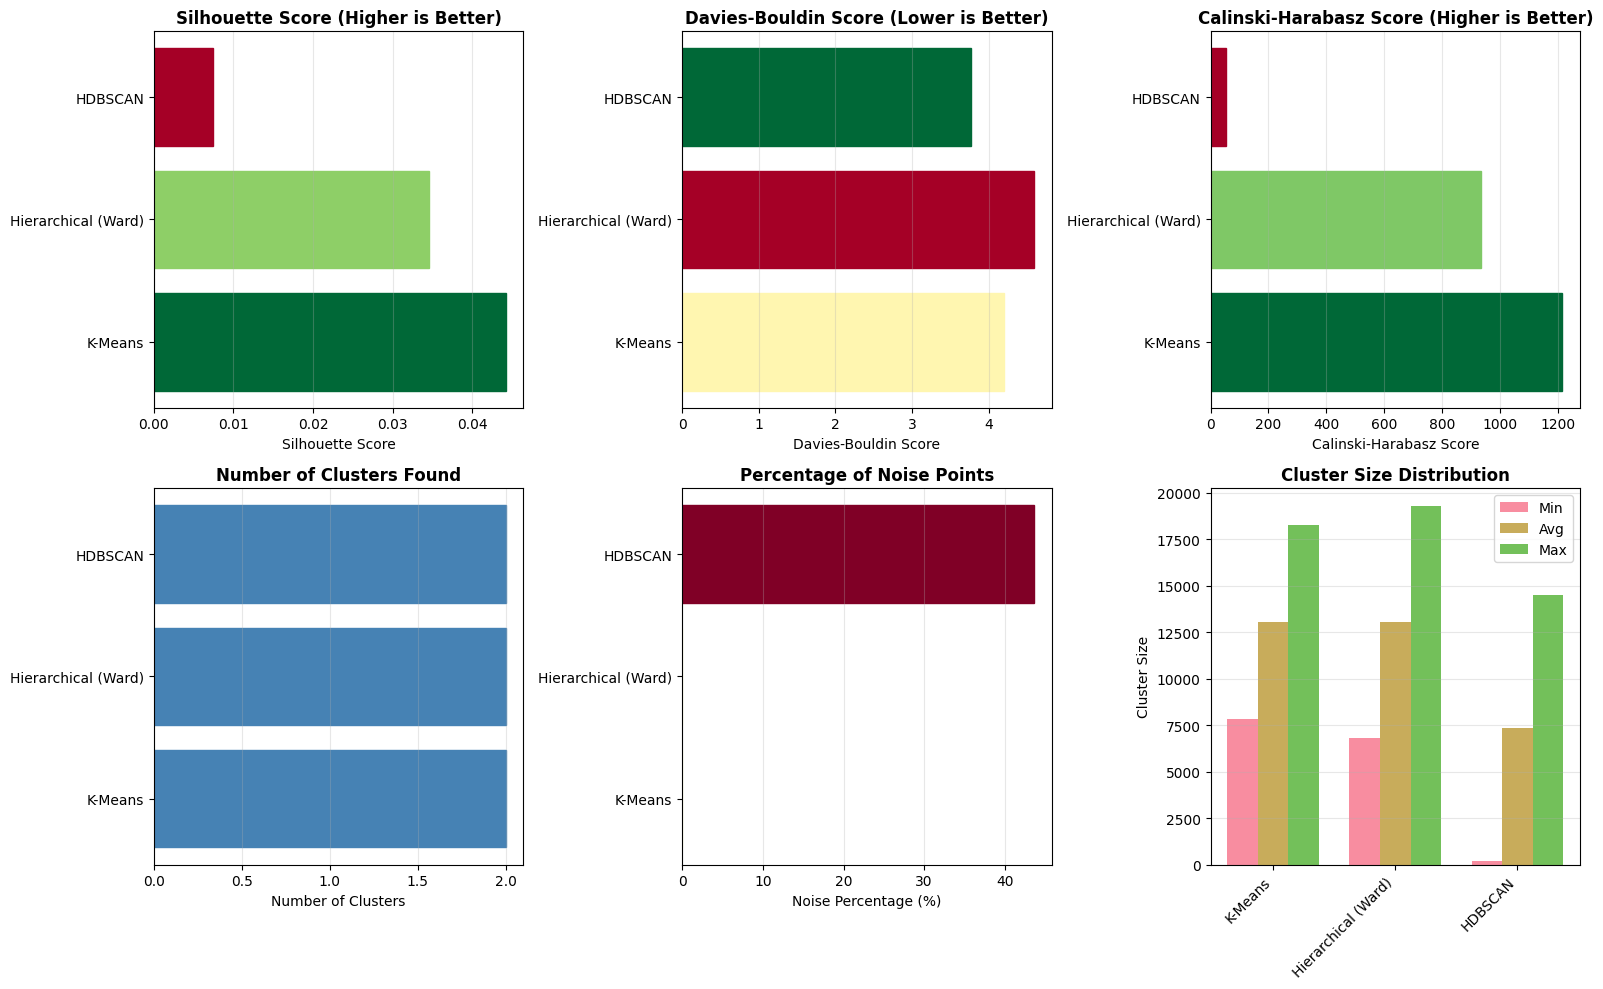


✓ Comparison complete and saved


In [43]:
# ============================================================================
# CELL 14: Compare Clustering Methods
# ============================================================================
print("\n" + "=" * 80)
print("COMPARING CLUSTERING METHODS")
print("=" * 80)

labels_dict = {
    "K-Means": labels_kmeans,
    "Hierarchical (Ward)": labels_hierarchical,
    "DBSCAN": labels_dbscan,
    "HDBSCAN": labels_hdbscan,
}

comparison_df = compare_clustering_methods(
    embeddings_pca, labels_dict, exclude_noise=True
)

print("\nComparison Results:")
print(comparison_df.to_string())

# Visualize comparison
fig = plot_clustering_metrics_comparison(comparison_df, figsize=(16, 10))
plt.savefig(
    "../data/results_resumes/clustering_methods_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("\n✓ Comparison complete and saved")



2D VISUALIZATION (t-SNE)
Computing t-SNE projection...


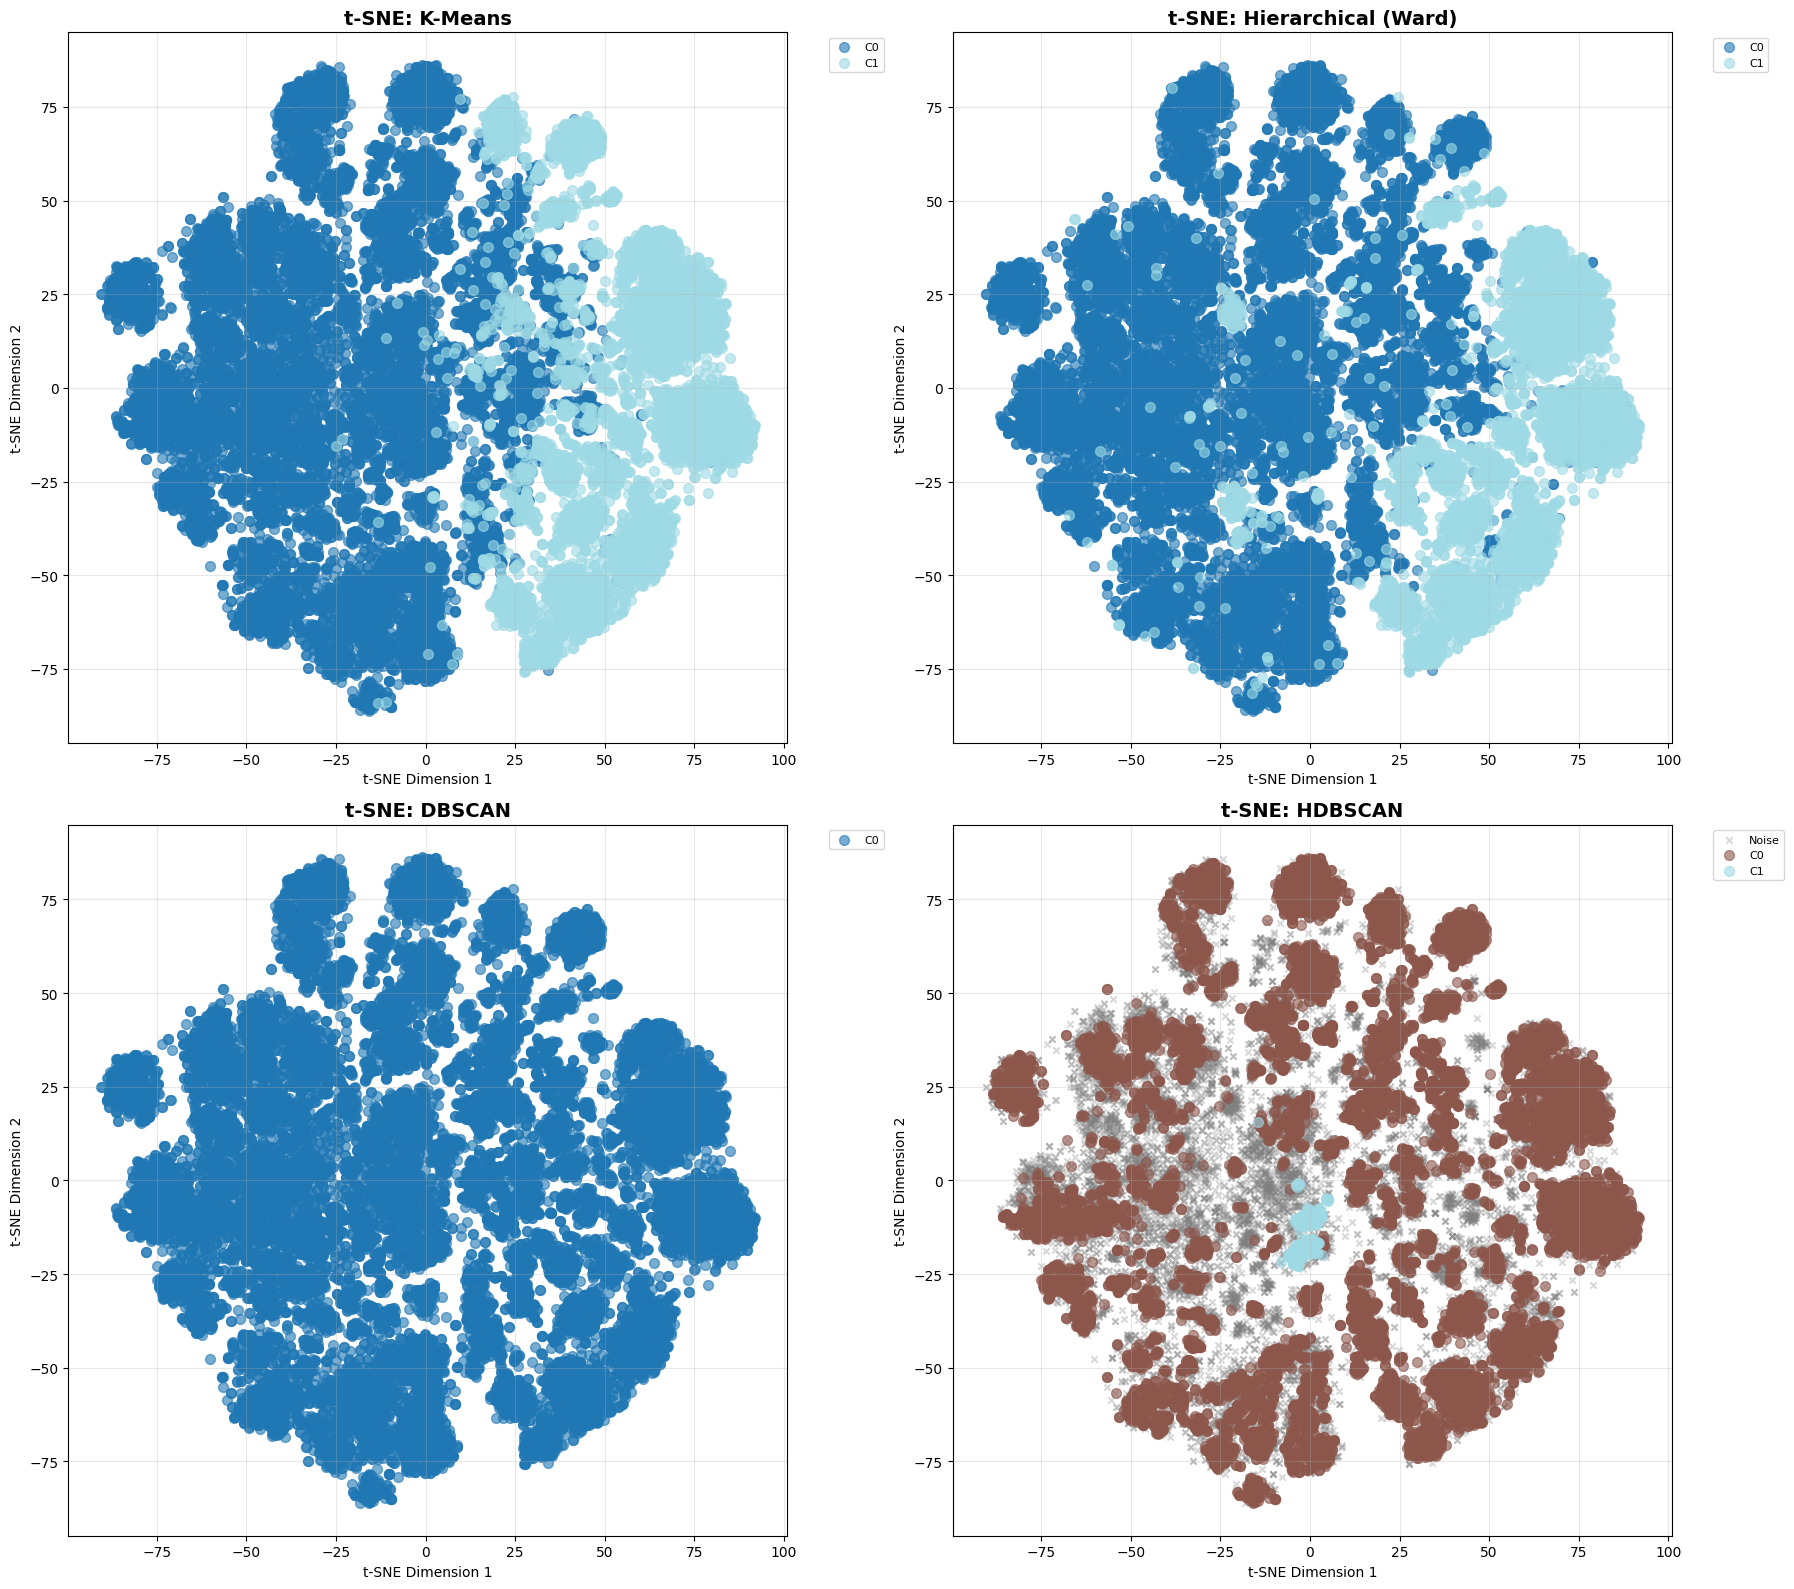

✓ t-SNE visualization complete


In [44]:
# ============================================================================
# CELL 15: 2D Visualization with t-SNE
# ============================================================================
print("\n" + "=" * 80)
print("2D VISUALIZATION (t-SNE)")
print("=" * 80)

from sklearn.manifold import TSNE

print("Computing t-SNE projection...")
tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=30)
embeddings_tsne = tsne.fit_transform(embeddings_pca)

# Plot each clustering method
fig, axes = plt.subplots(2, 2, figsize=(18, 16))

methods = ["K-Means", "Hierarchical (Ward)", "DBSCAN", "HDBSCAN"]
labels_list = [labels_kmeans, labels_hierarchical, labels_dbscan, labels_hdbscan]

for idx, (method, labels) in enumerate(zip(methods, labels_list)):
    ax = axes[idx // 2, idx % 2]

    unique_labels = sorted(set(labels))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))

    for label, color in zip(unique_labels, colors):
        mask = labels == label
        if label == -1:
            ax.scatter(
                embeddings_tsne[mask, 0],
                embeddings_tsne[mask, 1],
                c="gray",
                s=20,
                alpha=0.3,
                label="Noise",
                marker="x",
            )
        else:
            ax.scatter(
                embeddings_tsne[mask, 0],
                embeddings_tsne[mask, 1],
                c=[color],
                s=50,
                alpha=0.6,
                label=f"C{label}",
            )

    ax.set_title(f"t-SNE: {method}", fontsize=14, fontweight="bold")
    ax.set_xlabel("t-SNE Dimension 1")
    ax.set_ylabel("t-SNE Dimension 2")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../data/results_resumes/clustering_tsne_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("✓ t-SNE visualization complete")


2D VISUALIZATION (UMAP)
Computing UMAP projection...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



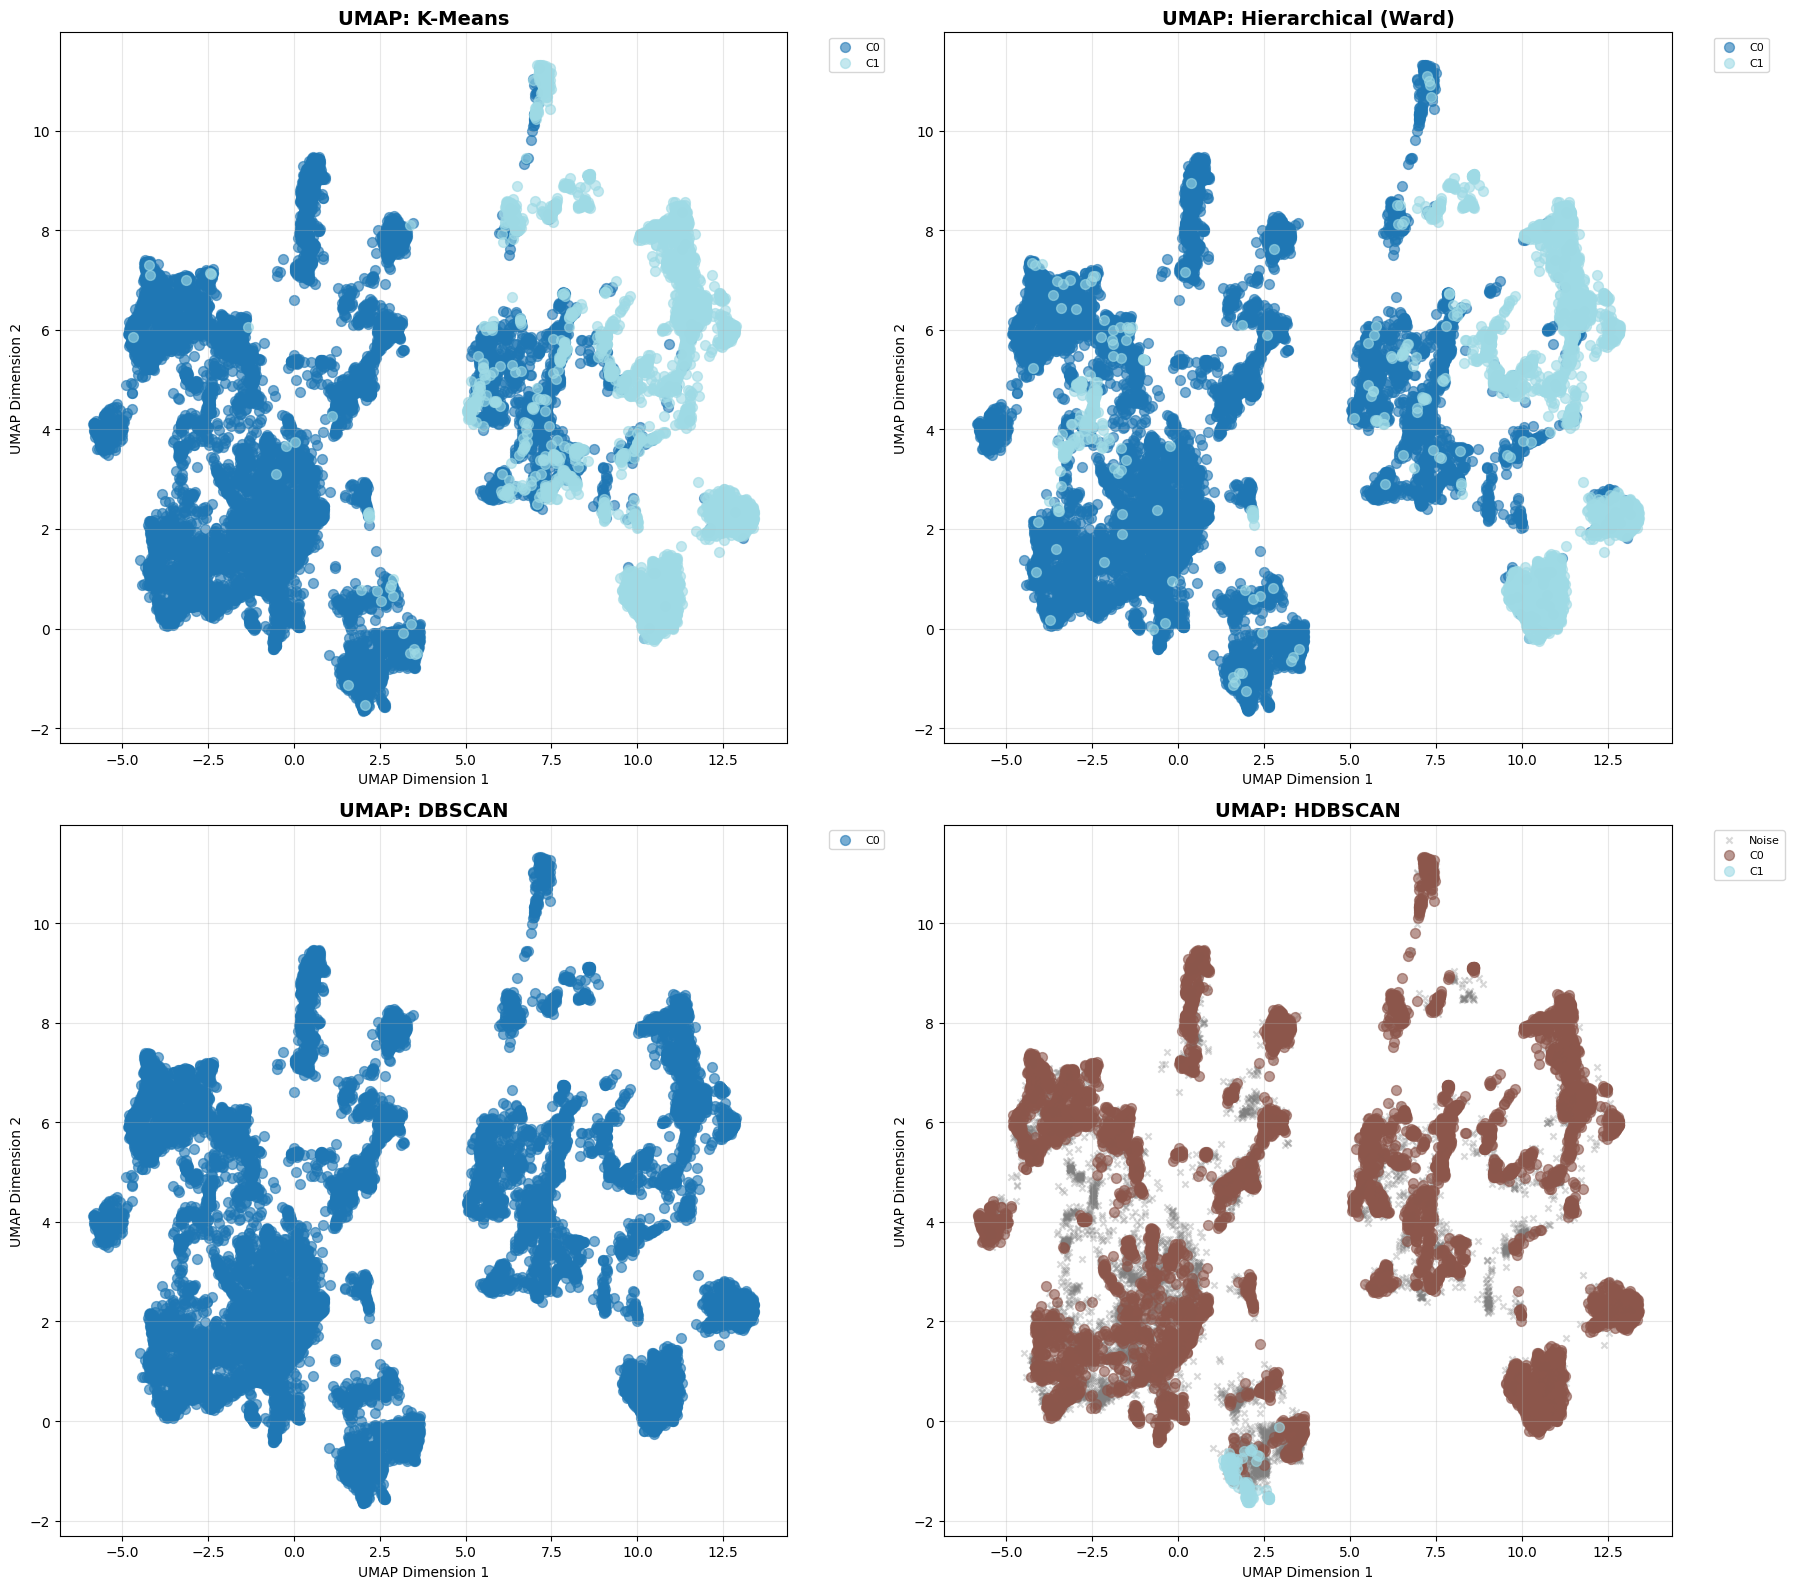

✓ UMAP visualization complete


In [46]:
# ============================================================================
# CELL 16: 2D Visualization with UMAP
# ============================================================================
print("\n" + "=" * 80)
print("2D VISUALIZATION (UMAP)")
print("=" * 80)

import umap

print("Computing UMAP projection...")
umap_model = umap.UMAP(
    n_components=2, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1
)
embeddings_umap = umap_model.fit_transform(embeddings_pca)

# Plot each clustering method
fig, axes = plt.subplots(2, 2, figsize=(18, 16))

for idx, (method, labels) in enumerate(zip(methods, labels_list)):
    ax = axes[idx // 2, idx % 2]

    unique_labels = sorted(set(labels))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))

    for label, color in zip(unique_labels, colors):
        mask = labels == label
        if label == -1:
            ax.scatter(
                embeddings_umap[mask, 0],
                embeddings_umap[mask, 1],
                c="gray",
                s=20,
                alpha=0.3,
                label="Noise",
                marker="x",
            )
        else:
            ax.scatter(
                embeddings_umap[mask, 0],
                embeddings_umap[mask, 1],
                c=[color],
                s=50,
                alpha=0.6,
                label=f"C{label}",
            )

    ax.set_title(f"UMAP: {method}", fontsize=14, fontweight="bold")
    ax.set_xlabel("UMAP Dimension 1")
    ax.set_ylabel("UMAP Dimension 2")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../data/results_resumes/clustering_umap_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("✓ UMAP visualization complete")


In [47]:
# ============================================================================
# CELL 17: 3D Interactive Visualization (K-Means)
# ============================================================================
print("\n" + "=" * 80)
print("3D INTERACTIVE VISUALIZATION")
print("=" * 80)

# Compute 3D UMAP for best method (K-Means)
umap_3d = umap.UMAP(
    n_components=3, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1
)
embeddings_umap_3d = umap_3d.fit_transform(embeddings_pca)

# Create interactive 3D plot
fig = plot_clusters_3d_interactive(
    embeddings_umap_3d,
    labels_kmeans,
    df,
    title="3D UMAP: K-Means Clustering",
    color_by=None,  # Color by cluster
    hover_cols=["type", "culture", "country", "label"],
)

fig.write_html("../data/results_resumes/clustering_3d_interactive.html")
fig.show()

print("✓ 3D interactive plot saved as HTML")


3D INTERACTIVE VISUALIZATION


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



✓ 3D interactive plot saved as HTML


In [21]:
# ============================================================================
# CELL 18: Culture & Country Correlation Analysis
# ============================================================================
print("\n" + "=" * 80)
print("CULTURE & COUNTRY CORRELATION ANALYSIS")
print("=" * 80)

# Analyze for K-Means (best method)
grouping_vars = ["culture", "country", "type"]

correlation_results = analyze_cluster_group_correlation(
    labels_kmeans, df, grouping_vars
)

print("\nCorrelation Results:")
print(correlation_results.to_string())

# Interpretation
print("\n" + "-" * 80)
print("INTERPRETATION")
print("-" * 80)
for _, row in correlation_results.iterrows():
    var = row["grouping_variable"]
    cramers = row["cramers_v"]
    effect = row["effect_size"]
    sig = "✓" if row["significant"] else "✗"

    print(f"\n{var}:")
    print(f"  Cramér's V: {cramers:.3f} ({effect} effect) {sig}")
    print(f"  Adjusted Rand Index: {row['adjusted_rand_index']:.3f}")
    print(f"  Normalized Mutual Info: {row['normalized_mutual_info']:.3f}")

2026-01-01 19:40:41,625 - src.analysis.correlation_analysis - INFO - Analyzing correlations for 3 grouping variables
2026-01-01 19:40:41,643 - src.analysis.correlation_analysis - INFO - culture - Cramér's V: 0.369, p-value: 0.0000e+00
2026-01-01 19:40:41,657 - src.analysis.correlation_analysis - INFO - country - Cramér's V: 0.444, p-value: 0.0000e+00
/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/src/analysis/correlation_analysis.py:75: RuntimeWarning:

invalid value encountered in divide

2026-01-01 19:40:41,668 - src.analysis.correlation_analysis - INFO - type - Cramér's V: nan, p-value: 1.0000e+00
2026-01-01 19:40:41,675 - src.analysis.correlation_analysis - INFO - Correlation analysis complete for 3 variables



CULTURE & COUNTRY CORRELATION ANALYSIS

Correlation Results:
  grouping_variable  cramers_v  chi2_p_value  significant effect_size  adjusted_rand_index  normalized_mutual_info  n_unique_values
1           country   0.444063           0.0         True       large              0.01518                0.057465               26
0           culture   0.369363           0.0         True       large              0.04429                0.059262                7
2              type        NaN           1.0        False       large              0.00000                0.000000                1

--------------------------------------------------------------------------------
INTERPRETATION
--------------------------------------------------------------------------------

country:
  Cramér's V: 0.444 (large effect) ✓
  Adjusted Rand Index: 0.015
  Normalized Mutual Info: 0.057

culture:
  Cramér's V: 0.369 (large effect) ✓
  Adjusted Rand Index: 0.044
  Normalized Mutual Info: 0.059

type:
  Cramér'


CLUSTER COMPOSITION BY CULTURE


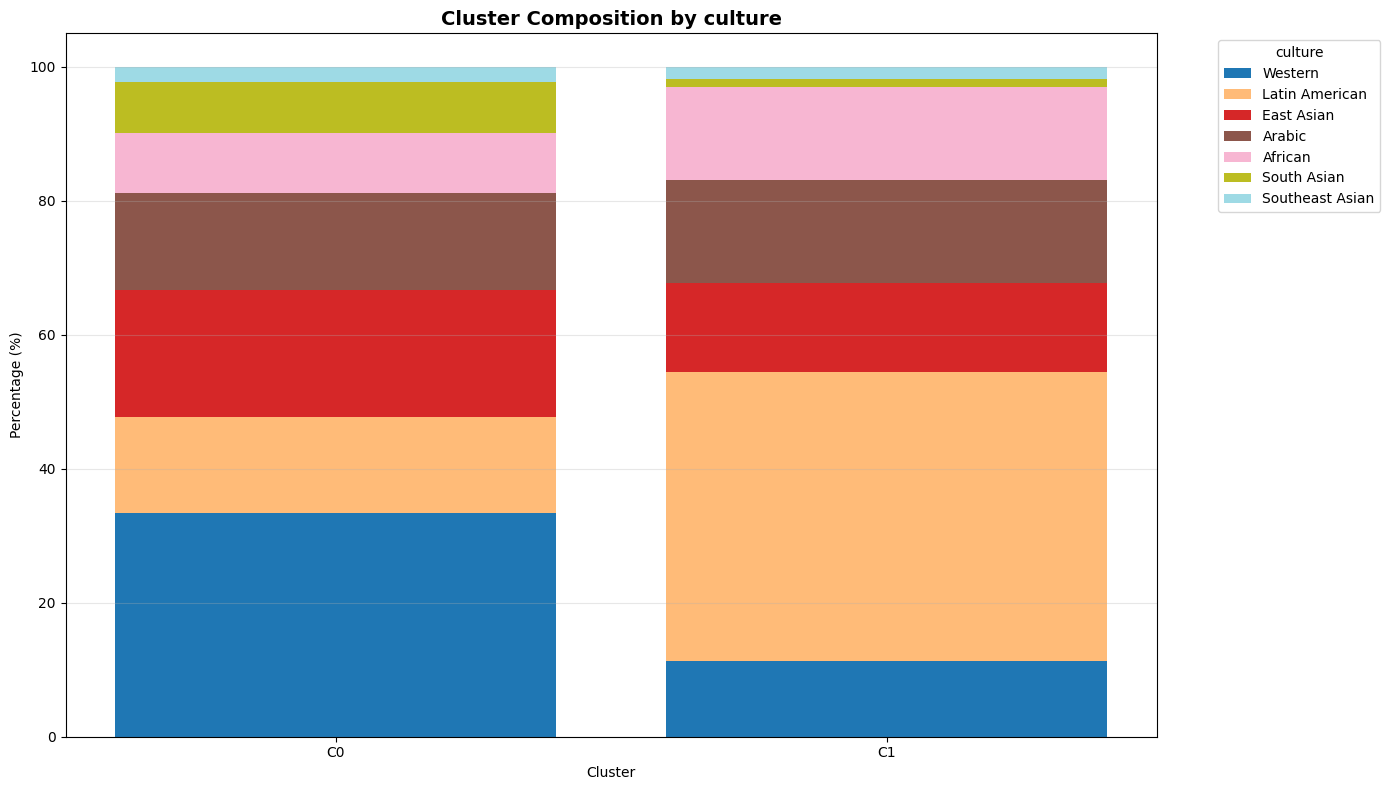

✓ Culture composition plot saved


In [22]:
# ============================================================================
# CELL 19: Cluster Composition by Culture
# ============================================================================
print("\n" + "=" * 80)
print("CLUSTER COMPOSITION BY CULTURE")
print("=" * 80)

fig = plot_cluster_composition(
    labels_kmeans,
    df,
    grouping_var="culture",
    top_n=df["culture"].nunique(),  # Show all cultures
    figsize=(14, 8),
)
plt.savefig(
    "../data/results_resumes/cluster_composition_culture.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("✓ Culture composition plot saved")


CLUSTER COMPOSITION BY COUNTRY


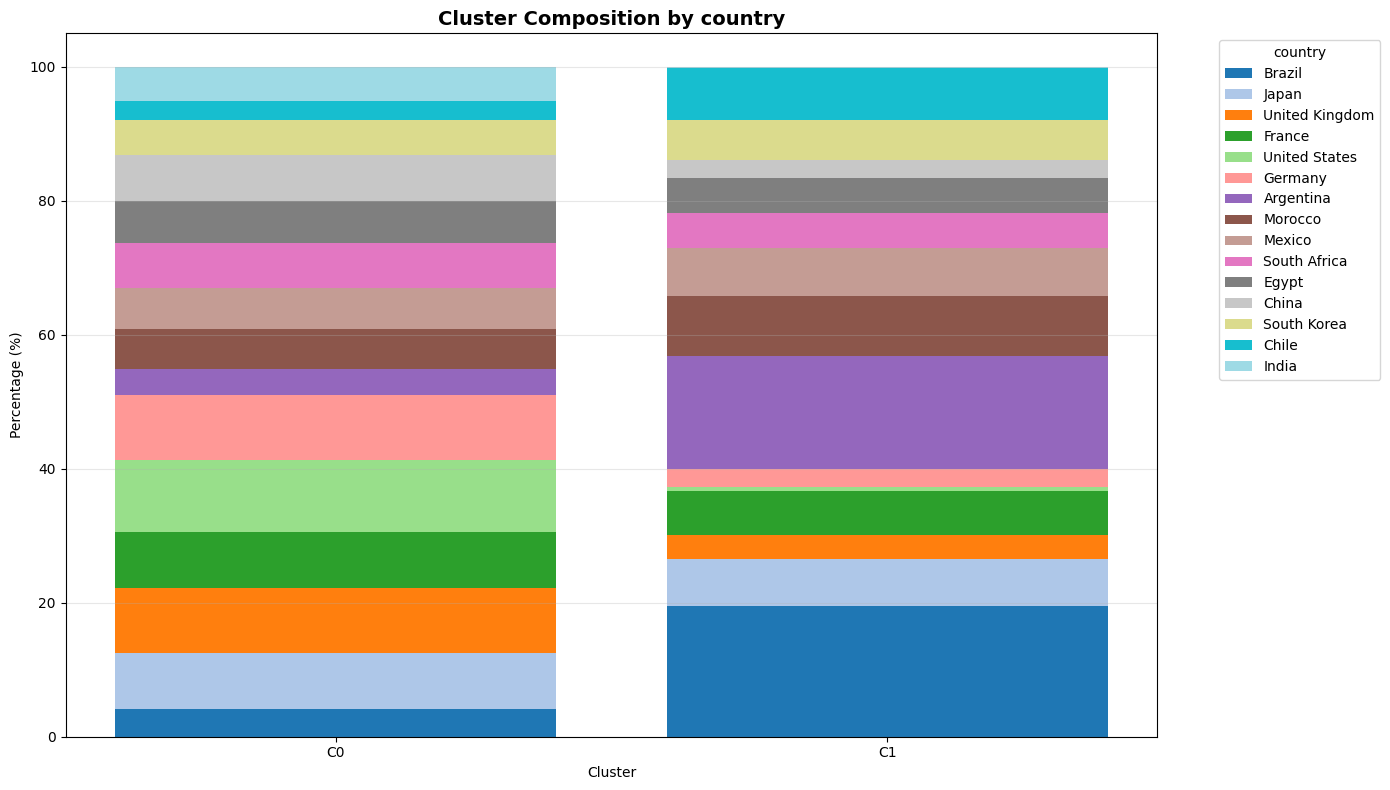

✓ Country composition plot saved


In [23]:
# ============================================================================
# CELL 20: Cluster Composition by Country
# ============================================================================
print("\n" + "=" * 80)
print("CLUSTER COMPOSITION BY COUNTRY")
print("=" * 80)

fig = plot_cluster_composition(
    labels_kmeans,
    df,
    grouping_var="country",
    top_n=15,  # Show top 15 countries
    figsize=(14, 8),
)
plt.savefig(
    "../data/results_resumes/cluster_composition_country.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("✓ Country composition plot saved")

In [24]:
# ============================================================================
# CELL 21: Purity Analysis
# ============================================================================
print("\n" + "=" * 80)
print("CLUSTER PURITY ANALYSIS")
print("=" * 80)

for var in ["culture", "country"]:
    print(f"\n{var.upper()} Purity:")
    print("-" * 40)

    purity_results = analyze_cluster_purity(labels_kmeans, df, var)

    print(f"Overall statistics:")
    for stat, value in purity_results["overall_stats"].items():
        print(f"  {stat}: {value:.3f}")

    print(f"\nPer cluster:")
    for cluster_id, stats in sorted(purity_results["per_cluster"].items()):
        print(
            f"  Cluster {cluster_id}: purity={stats['purity']:.3f}, "
            f"dominant={stats['dominant_value']} ({stats['dominant_count']}/{stats['total_count']})"
        )


CLUSTER PURITY ANALYSIS

CULTURE Purity:
----------------------------------------
Overall statistics:
  mean_purity: 0.383
  std_purity: 0.050
  min_purity: 0.333
  max_purity: 0.432
  median_purity: 0.383

Per cluster:
  Cluster 0: purity=0.333, dominant=Western (6146/18442)
  Cluster 1: purity=0.432, dominant=Latin American (3311/7656)

COUNTRY Purity:
----------------------------------------
Overall statistics:
  mean_purity: 0.128
  std_purity: 0.035
  min_purity: 0.093
  max_purity: 0.164
  median_purity: 0.128

Per cluster:
  Cluster 0: purity=0.093, dominant=United States (1714/18442)
  Cluster 1: purity=0.164, dominant=Brazil (1255/7656)


2026-01-01 19:41:39,180 - src.analysis.correlation_analysis - INFO - Analyzing hierarchical split order for ['country', 'culture']



HIERARCHICAL SPLIT ORDER: COUNTRIES vs CULTURES

Purity by depth:
----------------------------------------
n_clusters=2:
  country: 0.143
  culture: 0.456
n_clusters=3:
  country: 0.233
  culture: 0.666
n_clusters=4:
  country: 0.252
  culture: 0.678
n_clusters=5:
  country: 0.256
  culture: 0.692
n_clusters=6:
  country: 0.383
  culture: 0.736
n_clusters=7:
  country: 0.349
  culture: 0.678
n_clusters=8:
  country: 0.430
  culture: 0.715
n_clusters=9:
  country: 0.474
  culture: 0.732
n_clusters=10:
  country: 0.481
  culture: 0.755

----------------------------------------
EARLY SPLIT RANKING:
----------------------------------------
  culture: 0.600
  country: 0.209

Hierarchical clustering tends to split by 'culture' first


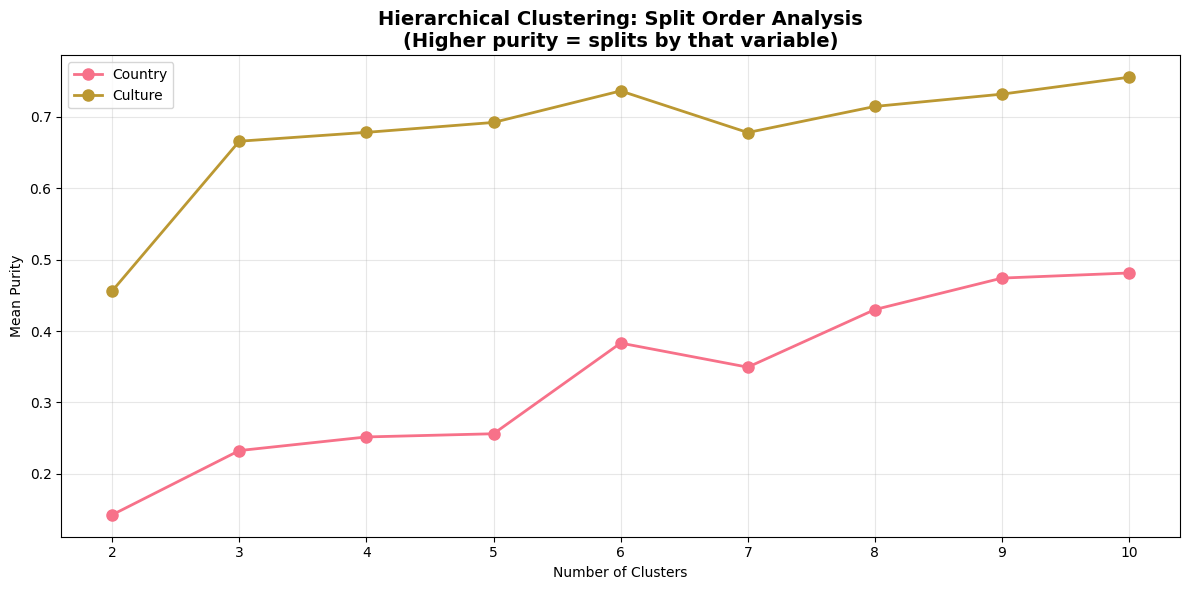

✓ Split order analysis complete


In [25]:
# ============================================================================
# CELL 22: Hierarchical Split Order Analysis
# ============================================================================
print("\n" + "=" * 80)
print("HIERARCHICAL SPLIT ORDER: COUNTRIES vs CULTURES")
print("=" * 80)

split_order_results = test_hierarchical_split_order(
    embeddings_pca,
    df,
    grouping_vars=["country", "culture"],
    method="ward",
    max_depth=10,
)

print("\nPurity by depth:")
print("-" * 40)
for depth, purities in sorted(split_order_results["purity_by_depth"].items()):
    print(f"n_clusters={depth}:")
    for var, purity in purities.items():
        print(f"  {var}: {purity:.3f}")

print("\n" + "-" * 40)
print("EARLY SPLIT RANKING:")
print("-" * 40)
for var, avg_purity in split_order_results["early_split_ranking"]:
    print(f"  {var}: {avg_purity:.3f}")

print("\n" + "=" * 80)
print(split_order_results["interpretation"])
print("=" * 80)

# Visualize split order
fig, ax = plt.subplots(figsize=(12, 6))

for var in ["country", "culture"]:
    depths = sorted(split_order_results["purity_by_depth"].keys())
    purities = [split_order_results["purity_by_depth"][d][var] for d in depths]
    ax.plot(depths, purities, "o-", linewidth=2, markersize=8, label=var.capitalize())

ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Mean Purity")
ax.set_title(
    "Hierarchical Clustering: Split Order Analysis\n(Higher purity = splits by that variable)",
    fontsize=14,
    fontweight="bold",
)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../data/results_resumes/hierarchical_split_order.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("✓ Split order analysis complete")

In [ ]:
# ============================================================================
# CELL 23: Contingency Tables
# ============================================================================
print("\n" + "=" * 80)
print("CONTINGENCY TABLES")
print("=" * 80)

# Culture contingency table
print("\nCluster × Culture:")
contingency_culture = calculate_contingency_table(labels_kmeans, df, "culture")
print(contingency_culture)

# Country contingency table (top countries only)
print("\nCluster × Country (top 10):")
top_countries = df["country"].value_counts().head(10).index
df_top_countries = df[df["country"].isin(top_countries)]
labels_top_countries = labels_kmeans[df["country"].isin(top_countries)]
contingency_country = calculate_contingency_table(
    labels_top_countries, df_top_countries, "country"
)
print(contingency_country)

In [26]:
# ============================================================================
# CELL 24: TF-IDF Keywords Extraction
# ============================================================================
print("\n" + "=" * 80)
print("TF-IDF KEYWORDS PER CLUSTER")
print("=" * 80)

# Load Wikipedia texts for keyword extraction
db = EntityDatabase("../data/entities.db")

# Prepare texts for each entity
texts = []
for _, row in tqdm(df.iterrows(), total=len(df), desc="Loading Wikipedia texts"):
    wiki_texts = db.get_wikipedia_texts(row["id"])

    # Combine texts from all languages
    combined_text = ""
    for lang in ["en", "fr", "ar"]:
        if lang in wiki_texts and wiki_texts[lang]["summary"]:
            combined_text += " " + wiki_texts[lang]["summary"]

    # Fallback to label if no text
    if not combined_text.strip():
        combined_text = row["label"]

    texts.append(combined_text.strip())

print(f"✓ Loaded {len(texts)} texts")

# Extract keywords
keywords_by_cluster = extract_tfidf_keywords(
    texts, labels_kmeans, n_keywords=10, ngram_range=(1, 3), min_df=2, max_df=0.7
)

print("\nTop Keywords by Cluster:")
print("=" * 80)
for cluster_id in sorted(keywords_by_cluster.keys()):
    keywords = keywords_by_cluster[cluster_id]
    n_entities = (labels_kmeans == cluster_id).sum()
    print(f"\nCluster {cluster_id} ({n_entities} entities):")
    print(f"  {', '.join(keywords)}")

2026-01-01 19:42:18,075 - src.data.database - INFO - Database initialized at ../data/entities.db



TF-IDF KEYWORDS PER CLUSTER


Loading Wikipedia texts: 100%|██████████| 26098/26098 [00:01<00:00, 15830.60it/s]
2026-01-01 19:42:19,737 - src.clustering.cluster_methods - INFO - Extracting TF-IDF keywords for 2 clusters


✓ Loaded 26098 texts


2026-01-01 19:42:34,778 - src.clustering.cluster_methods - INFO - Keyword extraction complete for 2 clusters



Top Keywords by Cluster:

Cluster 0 (18442 entities):
  he, was, en, il, his, du, she, des, born, né

Cluster 1 (7656 entities):
  he, مع, il, en, au, ونادي, football, played, du, footballeur


In [ ]:
# ============================================================================
# CELL 25: Cluster Summary Report
# ============================================================================
print("\n" + "=" * 80)
print("CLUSTER SUMMARY REPORT")
print("=" * 80)

for cluster_id in sorted(set(labels_kmeans)):
    mask = labels_kmeans == cluster_id
    cluster_df = df[mask]

    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id}")
    print(f"{'='*80}")

    print(f"\nSize: {len(cluster_df)} entities ({100*len(cluster_df)/len(df):.1f}%)")

    print(f"\nEntity Types:")
    for etype, count in cluster_df["type"].value_counts().head(5).items():
        print(f"  {etype}: {count} ({100*count/len(cluster_df):.1f}%)")

    print(f"\nCultures:")
    for culture, count in cluster_df["culture"].value_counts().items():
        print(f"  {culture}: {count} ({100*count/len(cluster_df):.1f}%)")

    print(f"\nTop Countries:")
    for country, count in cluster_df["country"].value_counts().head(5).items():
        print(f"  {country}: {count} ({100*count/len(cluster_df):.1f}%)")

    print(f"\nKeywords:")
    keywords = keywords_by_cluster.get(cluster_id, [])
    print(f"  {', '.join(keywords[:10])}")

    print(f"\nSample Entities:")
    for i, (_, entity) in enumerate(cluster_df.head(5).iterrows(), 1):
        print(f"  {i}. {entity['label']} ({entity['type']}, {entity['country']})")

In [ ]:

# ============================================================================
# CELL 26: Save Results
# ============================================================================
print("\n" + "=" * 80)
print("SAVING RESULTS")
print("=" * 80)

# Save DataFrame with cluster assignments
output_file = "../data/experiment/entities_with_clusters.csv"
df.to_csv(output_file, index=False)
print(f"✓ Saved entities with cluster assignments: {output_file}")

# Save clustering comparison
comparison_file = "../data/experiment/clustering_comparison.csv"
comparison_df.to_csv(comparison_file, index=False)
print(f"✓ Saved clustering comparison: {comparison_file}")

# Save correlation analysis
correlation_file = "../data/experiment/cluster_correlation_analysis.csv"
correlation_results.to_csv(correlation_file, index=False)
print(f"✓ Saved correlation analysis: {correlation_file}")

# Save keywords
import json

keywords_file = "../data/experiment/cluster_keywords.json"
with open(keywords_file, "w", encoding="utf-8") as f:
    json.dump(keywords_by_cluster, f, ensure_ascii=False, indent=2)
print(f"✓ Saved cluster keywords: {keywords_file}")

print("\n" + "=" * 80)
print("CLUSTERING ANALYSIS COMPLETE")
print("=" * 80)
print("\nSummary:")
print(f"  Best method: K-Means with k={optimal_k}")
print(f"  Total entities: {len(df)}")
print(f"  Number of clusters: {len(set(labels_kmeans))}")
print(
    f"  Culture correlation: {correlation_results[correlation_results['grouping_variable']=='culture']['cramers_v'].values[0]:.3f}"
)
print(
    f"  Country correlation: {correlation_results[correlation_results['grouping_variable']=='country']['cramers_v'].values[0]:.3f}"
)
print(f"\nAll results saved to: ../data/experiment/ and ../data/results_resumes/")
